
1. Dataset Overview
The dataset includes 1338 observations and seven variables: age, sex, BMI, number of children, smoking status, region, and insurance charges. The main objective is to predict the insurance charges using demographic and health related variables. This is a regression problem as our target variable, charges, is continuous. 

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('insurance.csv')
df.head() 

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [2]:
df.info()
df.describe()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [3]:
df['region'].value_counts()

region
southeast    364
southwest    325
northwest    325
northeast    324
Name: count, dtype: int64

In [4]:
df.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

There are no missing values, according to the results above. While sex, smoking status, and region are categorical factors, age, BMI, and children are numerical variables. 

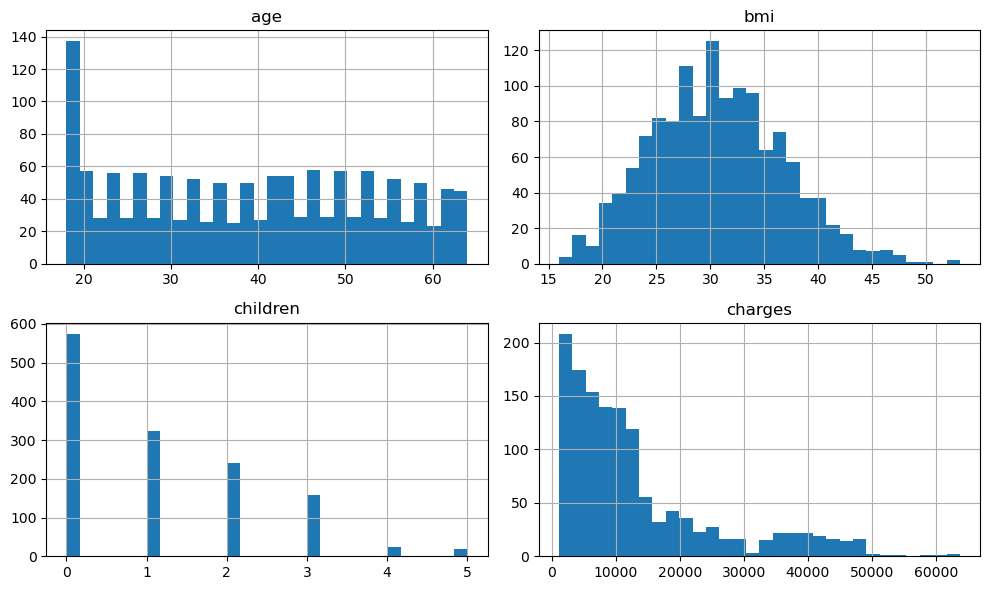

In [5]:
df.hist(bins=30, figsize=(10, 6))
plt.tight_layout()
plt.show()

In order to prevent the pattern from affecting the evaluation, I set aside a test set before continuing. I utilized a stratified split on smokers to ensure that all sets had the same number of smokers because smoking status has a significant impact on charges and only 20% of people smoke.

In [6]:
from sklearn.model_selection import train_test_split
strat_train_set, strat_test_set = train_test_split(df, test_size=0.2, random_state=42, stratify=df['smoker'])
len(strat_train_set), len(strat_test_set)

(1070, 268)

In [7]:
insurance = strat_train_set.copy()

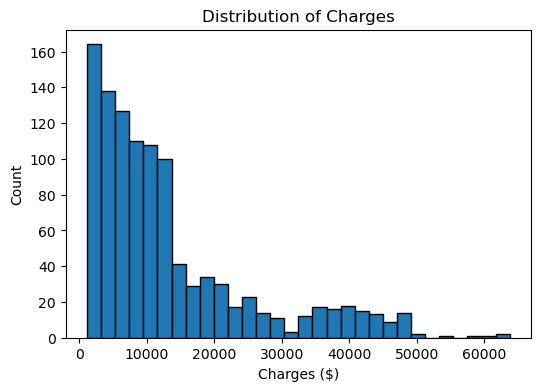

In [8]:
plt.figure(figsize=(6,4))
plt.hist(insurance['charges'], bins=30, edgecolor='black')
plt.title('Distribution of Charges')
plt.xlabel('Charges ($)')
plt.ylabel('Count')
plt.show()

The histogram shows that the distribution is rightly skewed, which means that most individuals have charges under $15000, and a few number of people have charges around or more than $60000. This aligns with our observation of earlier where the mean of $13270 is higher than the median $9382. 

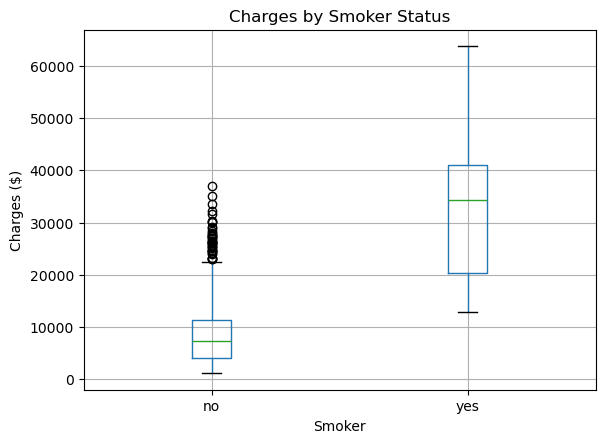

In [9]:
insurance.boxplot(column='charges', by='smoker')
plt.title('Charges by Smoker Status')
plt.suptitle('')
plt.xlabel('Smoker')
plt.ylabel('Charges ($)')
plt.show()

As seen, smokers have higher charges than non-smokers and are more spread out. This shows that smoking status is one of the strongest indicators of cost in the dataset. 

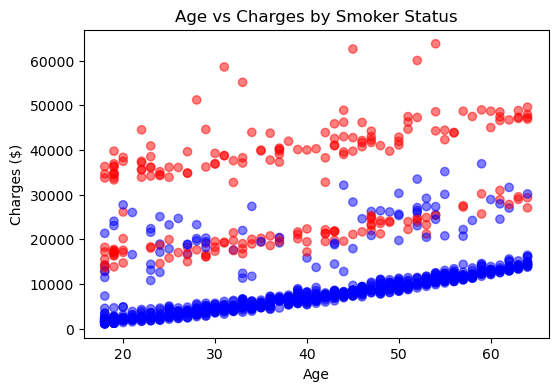

In [10]:
colors = insurance['smoker'].map({'yes': 'red','no' : 'blue'})
plt.figure(figsize=(6,4))
plt.scatter(insurance['age'], insurance['charges'], c=colors, alpha=0.5)
plt.title('Age vs Charges by Smoker Status')
plt.xlabel('Age')
plt.ylabel('Charges ($)')
plt.show()

This scatter plot shows us that as age moves up, the charges for both groups also increases, however, smokers pay way more than non-smokers at every age. Within the smokers group, they are further divided into two groups, where some pay more than others. This can also be linked to another factor like the BMI. 

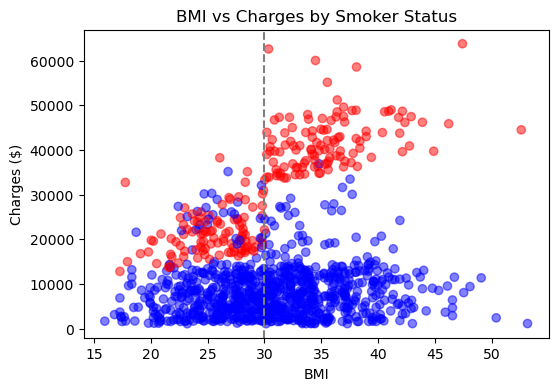

In [11]:
plt.figure(figsize=(6,4))
plt.scatter(insurance['bmi'], insurance['charges'], c=colors, alpha=0.5)
plt.axvline(30, color='gray', linestyle='--')
plt.title('BMI vs Charges by Smoker Status')
plt.xlabel('BMI')
plt.ylabel('Charges ($)')
plt.show()

This scatter plot confirms us that all the smokers who have a BMI above 30 have much higher charges than smokers with BMI lower than 30. This tells us that the effect of BMI is dependent on the smoking status. 

In [12]:
corr_matrix = insurance.corr(numeric_only=True)
corr_matrix['charges'].sort_values(ascending=False)

charges     1.000000
age         0.291370
bmi         0.185565
children    0.061811
Name: charges, dtype: float64

Along with BMI, age has the largest linear association with charges. Smoker status does not appear here because it is a categorical variable, but it is crucial, as can be seen in the images above. 

There were no missing values above. I added a median imputer to the pipeline in case there were any missing values in the new data. 
Additionally, I used the three preprocessing techniques:

1. One hot encoding that transforms categorical information into numerical indicators, such as region, sex, and smoking status.
2. Standard scaling for numerical characteristics such as children, age, and BMI. 
3. Log-transform to lessen the right skewness seen in EDA.

In [13]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler 
from sklearn.impute import SimpleImputer 
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer

num_attributes = ['age', 'bmi', 'children']
cat_attributes = ['sex', 'smoker', 'region']

num_pipeline = make_pipeline(SimpleImputer(strategy='median'), StandardScaler())
cat_pipeline = make_pipeline(SimpleImputer(strategy='most_frequent'), OneHotEncoder(handle_unknown='ignore'))

preprocessing = ColumnTransformer([
    ("num", num_pipeline, num_attributes),
    ("cat", cat_pipeline, cat_attributes)
])

In [14]:
insurance = strat_train_set.drop('charges' , axis=1)
insurance_labels = strat_train_set['charges'].copy()

In [15]:
for column in ['age', 'bmi']:
    q1 = insurance[column].quantile(0.25)
    q3 = insurance[column].quantile(0.75)
    iqr = q3 - q1

    flagged = (
        (insurance[column] < (q1 - 1.5 * iqr)) |
        (insurance[column] > (q3 + 1.5 * iqr))
    )
    print(f'{column}: {flagged.sum()} potential outliers')

from sklearn.ensemble import IsolationForest

isolation_forest = IsolationForest(contamination=0.01, random_state=42)
outlier_pred = isolation_forest.fit_predict(insurance[['age', 'bmi', 'children']])
(outlier_pred == -1).sum()

age: 0 potential outliers
bmi: 7 potential outliers


np.int64(11)

There were seven BMI outliers according to IQR and IsolationForest flagged 11 rows based on age, BMI and children. Because BMI includes actual information about medical charges and numbers up to 53 are medically credible rather than data-entry, I decided to keep these BMI values.

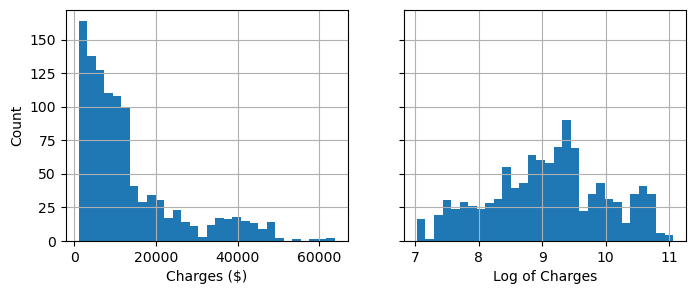

In [16]:
fig, axs = plt.subplots(1, 2, figsize=(8, 3), sharey=True)
insurance_labels.hist(ax=axs[0], bins=30)
insurance_labels.apply(np.log).hist(ax=axs[1], bins=30)
axs[0].set_xlabel('Charges ($)')
axs[1].set_xlabel('Log of Charges')
axs[0].set_ylabel('Count')
plt.show()


Log transformation makes the charges distribution less skewed. I did this by applying it with TransformedTargetRegressor which allows to train the model on log(charges) and convert the predictions back to dollars. 

In [17]:
from sklearn.linear_model import LinearRegression
from sklearn.compose import TransformedTargetRegressor

lin_reg = TransformedTargetRegressor(
    make_pipeline(preprocessing, LinearRegression()), 
    func=np.log, inverse_func=np.exp)
lin_reg.fit(insurance, insurance_labels)

,regressor,Pipeline(step...egression())])
,transformer,None
,func,<ufunc 'log'>
,inverse_func,<ufunc 'exp'>
,check_inverse,True
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False


I used linear regression to predict the log transformed insurance charges. The model is paired with preprocessing steps in a pipeline, so the scaling and Onehot encoding are fitted on the training data only, and the same fitted transformations are applied to the test data.

In [18]:
from sklearn.metrics import root_mean_squared_error

insurance_predictions = lin_reg.predict(insurance)
lin_rmse = root_mean_squared_error(insurance_labels, insurance_predictions)
lin_rmse

8514.453807767195

In [19]:
from sklearn.model_selection import cross_val_score

lin_rmses = -cross_val_score(lin_reg, insurance, insurance_labels, scoring='neg_root_mean_squared_error',cv=10)
pd.Series(lin_rmses).describe()

count       10.000000
mean      8592.991737
std        849.562336
min       7399.746678
25%       7855.920275
50%       8662.512027
75%       9127.673404
max      10135.834264
dtype: float64

In [20]:
X_test = strat_test_set.drop('charges', axis=1)
y_test = strat_test_set['charges'].copy()

final_predictions = lin_reg.predict(X_test)
final_rmse = root_mean_squared_error(y_test, final_predictions)
final_rmse

8331.572032628112

The model has a training RMSE of about \$8514 and a test RMSE of about \$8332. After running a cross validation check on the training set, it gives us a similar mean RMSE of about \$8592 with a standard deviation of \$850. The training, cross validation and the test errors are close to one another which means that there is no evidence of overfitting, that is, the model performs the same. The lower test error is within the cross validation range of scores and reflects the random differences between the two sets. The training error, however, is high which represents underfitting. Linear regression assumes that all the features have the same effect on charges, however, the BMI vs charges plots shows us that this is not true. BMI has little effect on non-smokers and smokers with a BMI higher than 30 have the highest charges. It makes it impossible for the model to capture this pattern and it ends up averaging the two variables, which results in more errors. 

In [21]:
%pip install causalml dowhy

Note: you may need to restart the kernel to use updated packages.


# Part 2: Causal Inference

Target (outcome): ** charges
Treatment: ** smoker (1 = yes, 0 = no)
Controls: ** age, bmi, sex, children, region 

Hypothesis: Even after controlling for all other factors, smoking increases insurance charges

In [22]:
from causalml.inference.meta import LRSRegressor, XGBTRegressor

df_causal = df.copy()
df_causal['smoker']= (df_causal['smoker']== 'yes').astype(int)

X_df = pd.get_dummies(df_causal[['age', 'bmi', 'children', 'sex', 'region']], drop_first=True).astype(float)
feature_names = X_df.columns.tolist()
X = X_df.values
y = df_causal['charges'].values
treatment = np.where(df_causal['smoker'] == 1, 'treatment', 'control')

In [23]:
lrs = LRSRegressor(control_name = 'control')
ate_lrs, lb_lrs, ub_lrs = lrs.estimate_ate(X, treatment, y)
print(f'LRS ATE: ${ate_lrs[0]:,.0f} (95% CI: ${lb_lrs[0]:,.0f}to ${ub_lrs[0]:,.0f})')

LRS ATE: $23,849 (95% CI: $22,722to $24,975)


In [24]:
xgbt = XGBTRegressor(control_name = 'control', random_state=42)
ate_xgb, lb_xgb, ub_xgb = xgbt.estimate_ate(X, treatment, y)
print(f'XGBT ATE: ${ate_xgb[0]:,.0f} (95% CI: ${lb_xgb[0]:,.0f} to ${ub_xgb[0]:,.0f})')

XGBT ATE: $23,872 (95% CI: $23,281 to $24,463)


[LightGBM] [Warning] There are no meaningful features which satisfy the provided configuration. Decreasing Dataset parameters min_data_in_bin or min_data_in_leaf and re-constructing Dataset might resolve this warning.
[LightGBM] [Info] Total Bins 0
[LightGBM] [Info] Number of data points in the train set: 2, number of used features: 0
[LightGBM] [Info] Start training from score 0.500000
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the split requirements
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the split requirements
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the split requirements
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the split requirements
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the split requirements
[LightGBM] [Warning] Stopped training because there are no more leaves that meet the split

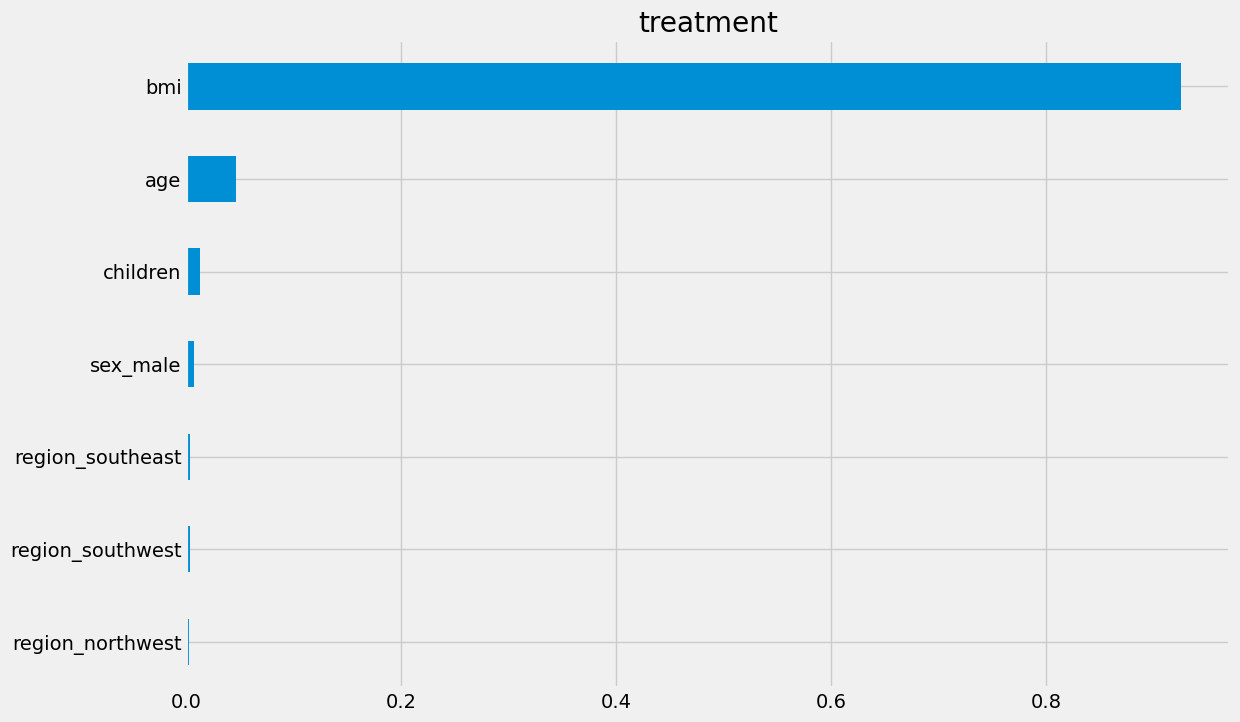

In [25]:
tau_xgb = xgbt.fit_predict(X, treatment, y)
xgbt.plot_importance( X=X, tau=tau_xgb, normalize=True, method='auto', features =feature_names)

Both models confirm that smoking increases insurance charges by about $23,850 on average, and the effect is much larger for smokers with a high BMI. 

### DoWhy


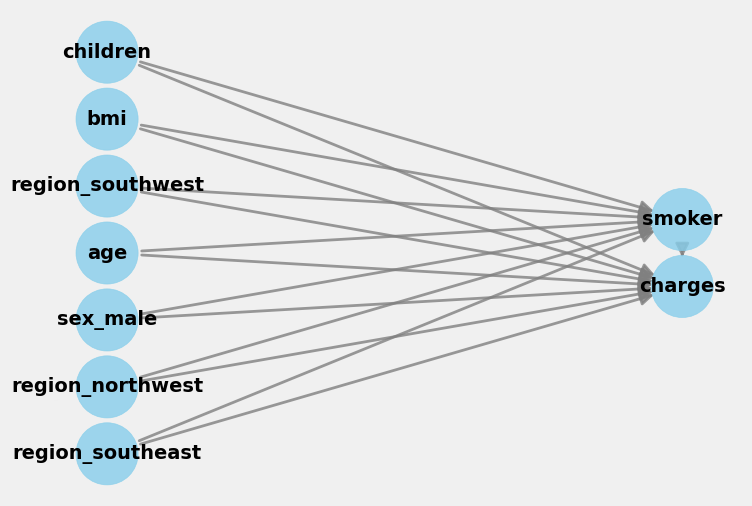

In [26]:
from dowhy import CausalModel 

df_dowhy = pd.get_dummies(df_causal, columns=['sex', 'region'], drop_first=True, dtype=float)
common_causes = [c for c in df_dowhy.columns if c not in ['smoker', 'charges']]

model = CausalModel(
    data=df_dowhy,
    treatment='smoker',
    outcome='charges',
    common_causes=common_causes
)
model.view_model()


In [27]:
estimand = model.identify_effect(proceed_when_unidentifiable=True)
print(estimand)

Estimand type: EstimandType.NONPARAMETRIC_ATE

### Estimand : 1
Estimand name: backdoor
Estimand expression:
    d                                                                          ↪
─────────(E[charges|region_southeast,region_northwest,sex_male,age,region_sout ↪
d[smoker]                                                                      ↪

↪                     
↪ hwest,bmi,children])
↪                     
Estimand assumption 1, Unconfoundedness: If U→{smoker} and U→charges then P(charges|smoker,region_southeast,region_northwest,sex_male,age,region_southwest,bmi,children,U) = P(charges|smoker,region_southeast,region_northwest,sex_male,age,region_southwest,bmi,children)

### Estimand : 2
Estimand name: iv
No such variable(s) found!

### Estimand : 3
Estimand name: frontdoor
No such variable(s) found!

### Estimand : 4
Estimand name: general_adjustment
Estimand expression:
    d                                                                          ↪
─────────(E[charges|reg

In [28]:
estimate = model.estimate_effect(estimand, method_name='backdoor.linear_regression')
print(f'DoWhy estimated effect of smoking: ${estimate.value:,.0f}')

DoWhy estimated effect of smoking: $23,849


In [29]:
print(model.refute_estimate(estimand, estimate, method_name='random_common_cause'))
print(model.refute_estimate(estimand, estimate, method_name='placebo_treatment_refuter'))

Refute: Add a random common cause
Estimated effect:23848.534541913163
New effect:23849.871099399486
p value:0.96

Refute: Use a Placebo Treatment
Estimated effect:23848.534541913163
New effect:-55.50124588387435
p value:0.88



## Conclusion 

Even after controlling for all other factors, smoking increases insurance charges. This is supported by the results. All three methods produced almost the same estimate. The LRSRegressor estimated an effect of $23,849, the XGBTRegressor estimated $23,872, and DoWhy estimated $23,849. This means that, on average, yearly insurance charges increases by roughly $23,850 for smokers.
The feature importance plot shows that BMI is the main factor that changes how strongly smoking affects charges, making up about 92% of the importance. This is consistent with the earlier EDA, where smokers that had a BMI above 30 faced higher charges than others. 
The refutation tests also helped increase the confidence in the result. Adding a random common cause left the estimate unchanged, and replacing smoking with a placebo treatment reduced the effect to about -$105. This shows that effect is driven by smoking and not by chances. 
However, there are some limitations. As the data is observational, unmeasured factors like diet or exercise can still influence the results. BMI is also partly affected by smoking, hence, it makes an imperfect control. Also the DoWhy model assumed that the relationship was linear, even though the EDA showed that smoking and BMI interact with one another. 

